# Assignment 10: PCA on the Breast Cancer Dataset

Apply PCA to a dataset with multiple numerical features, determine how many components are needed, how much variance they explain, build a 2D representation, and explain what's retained and what's lost.

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import scipy.cluster.hierarchy as sch

## Load the Dataset

The Breast Cancer Wisconsin dataset from scikit-learn: 569 samples, 30 numeric measurements per sample (mean radius, mean texture, mean area, etc.), and a known diagnosis (malignant or benign) kept aside just to check later whether PCA preserves that separation.

In [8]:
data = load_breast_cancer()
df = pd.DataFrame(data.data, columns=data.feature_names)

print("Shape:", df.shape)
df.head()

Shape: (569, 30)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


## Scale the Data

`mean area` is in the hundreds while `mean smoothness` is a small decimal, so without scaling PCA would treat `mean area` as far more important purely because of its units. `StandardScaler` puts every feature on the same footing first.

In [9]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df.values)

print("Scaled feature means:", X_scaled.mean(axis=0).round(2)[:5], "...")
print("Scaled feature stds :", X_scaled.std(axis=0).round(2)[:5], "...")

Scaled feature means: [-0.  0. -0. -0. -0.] ...
Scaled feature stds : [1. 1. 1. 1. 1.] ...


## Number of Components Required

To find how many components are *required*, fit PCA with all 30 components first and track how the variance adds up as more components are included.

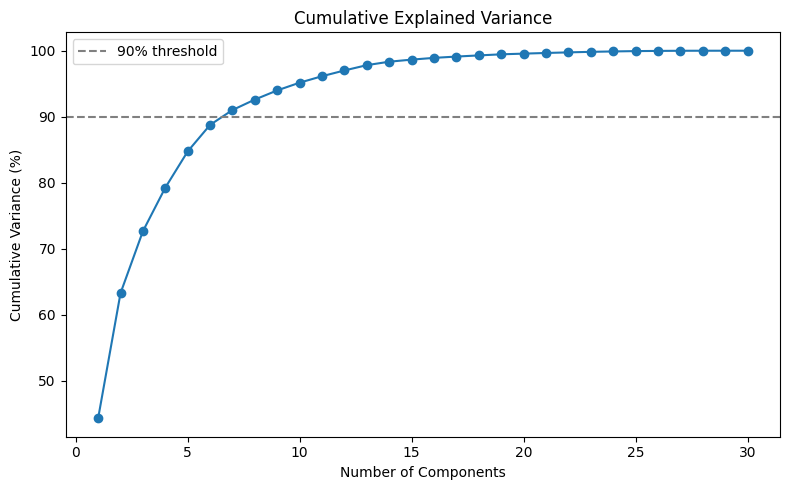

Components needed for >=90% variance: 7


In [10]:
pca_full = PCA(n_components=None)
pca_full.fit(X_scaled)

ratios = pca_full.explained_variance_ratio_
cumulative = np.cumsum(ratios)

plt.figure(figsize=(8, 5))
components = np.arange(1, len(ratios) + 1)
plt.plot(components, cumulative * 100, marker="o")
plt.axhline(90, color="gray", linestyle="--", label="90% threshold")
plt.title("Cumulative Explained Variance")
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Variance (%)")
plt.legend()
plt.tight_layout()
plt.show()

k90 = np.argmax(cumulative >= 0.90) + 1
print(f"Components needed for >=90% variance: {k90}")

**7 components are needed to keep at least 90% of the total variance.** The curve rises fast at first (PC1 alone covers 44.3%) and then flattens, so most of the information is concentrated in the first few components.

## Explained Variance

In [11]:
variance_table = pd.DataFrame({
    "Component": [f"PC{i}" for i in components],
    "Explained Variance (%)": np.round(ratios * 100, 2),
    "Cumulative Variance (%)": np.round(cumulative * 100, 2),
}).set_index("Component")

variance_table.head(10)

,Explained Variance (%),Cumulative Variance (%)
Component,,
PC1,44.27,44.27
PC2,18.97,63.24
PC3,9.39,72.64
PC4,6.60,79.24
PC5,5.50,84.73
PC6,4.02,88.76
PC7,2.25,91.01
PC8,1.59,92.60
PC9,1.39,93.99


## 2D Representation of the Data

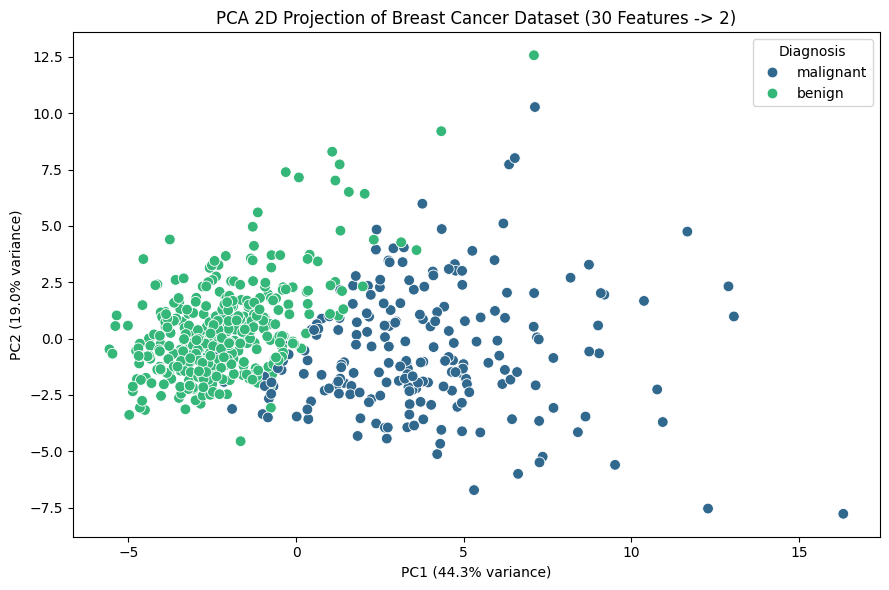

Variance kept by these 2 components: 63.24%


In [12]:
pca_2d_model = PCA(n_components=2)
pca_2d = pca_2d_model.fit_transform(X_scaled)

pca_df = pd.DataFrame(pca_2d, columns=["PC1", "PC2"])
pca_df["Diagnosis"] = [data.target_names[t] for t in data.target]

plt.figure(figsize=(9, 6))
sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="Diagnosis", palette="viridis", s=60)
plt.title("PCA 2D Projection of Breast Cancer Dataset (30 Features -> 2)")
plt.xlabel(f"PC1 ({pca_2d_model.explained_variance_ratio_[0]*100:.1f}% variance)")
plt.ylabel(f"PC2 ({pca_2d_model.explained_variance_ratio_[1]*100:.1f}% variance)")
plt.tight_layout()
plt.show()

print(f"Variance kept by these 2 components: {pca_2d_model.explained_variance_ratio_.sum()*100:.2f}%")

## Hierarchical Clustering: Dendrogram

The dendrogram shows how the samples join together into groups, step by step. It helps us see how many clusters the data naturally has, instead of guessing.

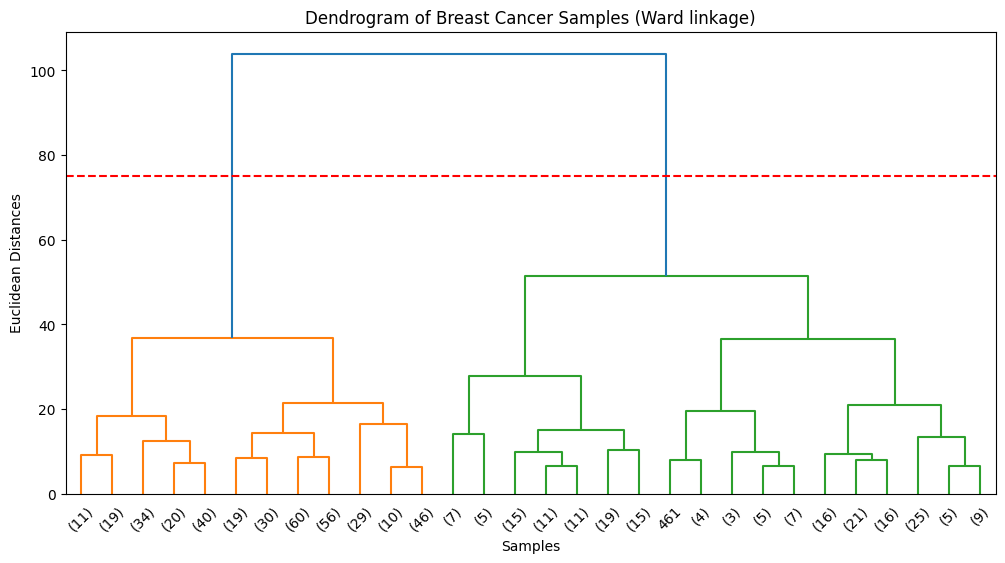

In [13]:
plt.figure(figsize=(12, 6))
plt.title('Dendrogram of Breast Cancer Samples (Ward linkage)')
plt.xlabel('Samples')
plt.ylabel('Euclidean Distances')
# 'ward' minimizes the variance of clusters being merged
# truncate_mode='lastp' shows only the last 30 merges so the chart is readable
dendrogram = sch.dendrogram(sch.linkage(pca_df[['PC1', 'PC2']], method='ward'), truncate_mode='lastp', p=30)
plt.axhline(y=75, color='r', linestyle='--')  # cut line
plt.show()

The biggest gap is at the top of the tree, so cutting there (red line) gives **2 clusters**. This matches the 2 diagnoses in the data: malignant and benign.

## What's Retained and What's Lost

**Retained:** The 2D projection keeps 63.24% of the total variance, and the plot shows a fairly clean split between malignant and benign along PC1, so the two most important axes of variation line up closely with the actual diagnosis, even though PCA was never told the diagnosis.

**Lost:** The other 36.76% is spread across the remaining 28 components. No single original measurement (e.g. `mean radius` or `mean texture`) survives on its own, PC1 and PC2 are each a mix of all 30 original features, so the plot shows overall similarity between samples, not any one specific measurement. There's also some overlap between the two classes near the boundary in the plot, which is exactly the kind of finer detail that the dropped components would help resolve. Keeping 90% of the information would take 7 components, so the 2D view is useful for visualizing the data, not for fully representing it.